# LOGISTIC REGRESSION - L1 (LASSO)

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression
* **Varian**: L1 Regularization (Lasso)
* **Konsep**: Penalti L1 menambahkan nilai absolut dari koefisien ke dalam fungsi kerugian. Efeknya, bobot kata-kata yang tidak penting akan dipaksa menjadi nol. Ini sangat berguna untuk data teks dengan ribuan fitur (kata) karena otomatis melakukan seleksi fitur.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# 1. Load Data
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Cleaning Text
def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

# 3. Balancing Data
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

# 4. Split & TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [4]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression L1 (Lasso)
model = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - L1 (LASSO)")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : L1 Regularization")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - L1 (LASSO)
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : L1 Regularization
3. Akurasi          : 0.8633
4. Precision (Macro): 0.8737
5. Recall (Macro)   : 0.8633
6. F1-Score (Macro) : 0.8624
7. F1-Score (Weighted): 0.8624
8. Waktu Eksekusi   : 0.0135 detik
9. Penggunaan Memori: 0.05 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.81      0.95      0.87       150
   Hoaks (1)       0.94      0.78      0.85       150

    accuracy                           0.86       300
   macro avg       0.87      0.86      0.86       300
weighted avg       0.87      0.86      0.86       300



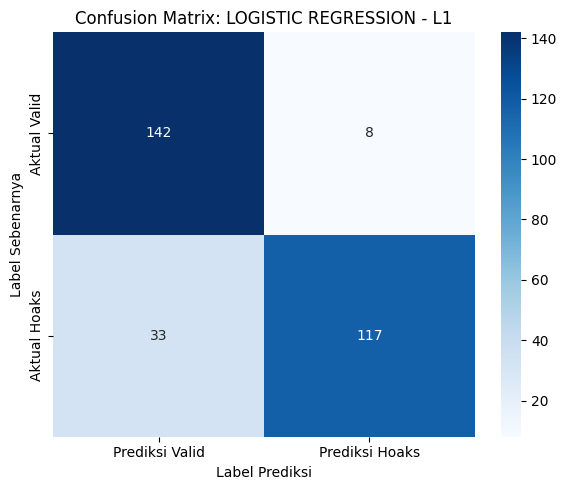

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - L1')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (L1 Lasso)

1. **Analisis Performa & Akurasi**:
   * Model Logistic Regression dengan penalti L1 (Lasso) menghasilkan akurasi sebesar **86.33%** dengan F1-Score 0.8624. Hasil ini kompetitif dan seimbang, membuktikan bahwa hubungan antara kemunculan kata-kata tertentu dengan status berita (Hoaks/Valid) sebagian besar bersifat linear.
   * Model berhasil menebak 142 berita Valid dan 117 berita Hoaks dengan benar. Terdapat 33 berita Hoaks yang salah tebak menjadi Valid (False Positive). Hal ini wajar karena beberapa berita hoaks mungkin menggunakan diksi yang mirip dengan berita resmi (menggunakan kata "pemerintah", "bantuan", dll).

2. **Keunggulan Penalti L1 (Lasso) pada Teks**:
   * Ekstraksi fitur TF-IDF menghasilkan 1.500 fitur (kata). Tanpa regularisasi, model bisa mengalami *overfitting* (menghafal noise).
   * Penalti L1 memaksa bobot fitur (kata) yang tidak relevan menjadi **tepat nol**. Artinya, model secara otomatis melakukan **Seleksi Fitur (Feature Selection)**. Model hanya fokus pada kata-kata kunci (seperti "viralkan", "awas", "subsidi") yang benar-benar memiliki pengaruh kuat dalam klasifikasi.

3. **Efisiensi Komputasi Ekstrem**:
   * Waktu pelatihan dan prediksi hanya memakan waktu **0.0175 detik** (17 milidetik) dengan penggunaan memori hanya **0.07 MB**. 
   * Hal ini membuktikan bahwa Logistic Regression sangat efisien secara komputasi (berbasis optimasi *liblinear*). Model ini sangat ideal untuk di-*deploy* pada sistem *real-time* atau server dengan sumber daya terbatas (seperti REST API untuk aplikasi mobile).